# E4 — Natural-Language Instructions + Open-Vocabulary Grounding

**Goal:** accept free-form instructions such as *"could you get rid of the guy on the left?"*, and objects outside the 80 COCO classes, such as *"remove the hat"*.

E0 to E3 used a regex parser and YOLOv8n, so they only worked with fixed sentence patterns and COCO class names.

| System | Parser | Grounding | Segmentation | Removal |
|---|---|---|---|---|
| **A** (E3 baseline) | regex | YOLOv8n (80 COCO classes) | MobileSAM | MI-GAN |
| **B** | local LLM (Qwen2.5-0.5B, 4-bit) | YOLOv8n | MobileSAM | MI-GAN |
| **C** | local LLM | YOLO-World-S (open vocabulary) | MobileSAM | MI-GAN |
| **D** (optional) | local LLM | YOLOE-11S-seg (open vocabulary, returns masks) | — | MI-GAN |

Everything runs on the CPU.

**Outputs:**
* `benchmarks/e4_parser_eval.csv`
* `benchmarks/e4_grounding_eval.csv`
* `benchmarks/e4_benchmark.csv`
* `benchmarks/e4_model_sizes.csv`
* images in `results/E4/`

⏱️ Runtime on 2-vCPU Colab is about 10–15 min, mostly downloads.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!pip install -q -U ultralytics onnxruntime
!pip install -q git+https://github.com/ChaoningZhang/MobileSAM.git

# CLIP text encoder used by YOLO-World's set_classes()
!pip install -q git+https://github.com/ultralytics/CLIP.git

# llama.cpp runtime for the 4-bit LLM. Prebuilt CPU wheel only -> fails fast instead of a ~15 min source build.
# If it fails, the notebook automatically uses the transformers backend (bigger + slower, but works).
!pip install -q --only-binary=llama-cpp-python llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu || echo "No prebuilt llama-cpp-python wheel -> transformers backend will be used"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.9/23.9 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.3 MB/s eta 0:00:00


In [3]:
import os
import re
import gc
import sys
import json
import time
import glob
import platform
import subprocess
import threading
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import ultralytics
from ultralytics import YOLO
from mobile_sam import sam_model_registry, SamPredictor
import onnxruntime as ort

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("ONNX Runtime:", ort.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python: 3.13.15
PyTorch: 2.11.0+cpu
Ultralytics: 8.4.165
ONNX Runtime: 1.30.0


In [4]:
BASE_DIR = "/content/drive/MyDrive/inter_IIT/Task_2/"
IMAGE_DIR = BASE_DIR
ASSET_DIR = os.path.join(BASE_DIR, "assets")
MODEL_DIR = os.path.join(BASE_DIR, "models")
BENCHMARK_DIR = os.path.join(BASE_DIR, "benchmarks")
RESULTS_DIR = os.path.join(BASE_DIR, "results", "E4")

for d in [MODEL_DIR, BENCHMARK_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

DEVICE = "cpu"
# E0-E3 used cpu_count() // 2 (= 1 thread on 2-vCPU Colab). Use every core.
CPU_THREADS = os.cpu_count() or 2
torch.set_num_threads(CPU_THREADS)
cv2.setNumThreads(CPU_THREADS)
SEED = 42


def cpu_model_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor()


SYSTEM_INFO = {
    "cpu": cpu_model_name(),
    "logical_cores": os.cpu_count(),
    "threads_used": CPU_THREADS,
    "ram_gb": round(psutil.virtual_memory().total / 2**30, 2),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "onnxruntime": ort.__version__,
    "opencv": cv2.__version__,
    "ultralytics": ultralytics.__version__,
}
print(json.dumps(SYSTEM_INFO, indent=2))

with open(os.path.join(BENCHMARK_DIR, "e4_system_info.json"), "w") as f:
    json.dump(SYSTEM_INFO, f, indent=2)

{
  "cpu": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "logical_cores": 2,
  "threads_used": 2,
  "ram_gb": 12.67,
  "python": "3.13.15",
  "torch": "2.11.0+cpu",
  "onnxruntime": "1.30.0",
  "opencv": "4.14.0",
  "ultralytics": "8.4.165"
}


In [5]:
def file_mb(path):
    return os.path.getsize(path) / 2**20


def params_m(module):
    return sum(p.numel() for p in module.parameters()) / 1e6


def fp32_mb(module):
    """In-memory fp32 weight size (params x 4 bytes)."""
    return sum(p.numel() for p in module.parameters()) * 4 / 2**20


def rss_mb():
    return psutil.Process().memory_info().rss / 2**20


def read_image(name):
    path = name if os.path.isabs(name) else os.path.join(IMAGE_DIR, name)
    img = cv2.imread(path)
    if img is None:  # some test images are AVIF files saved as .jpg
        img = cv2.cvtColor(np.array(Image.open(path).convert("RGB")), cv2.COLOR_RGB2BGR)
    return img


def to_rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def slug(text, n=40):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")[:n]


def save_image(img, name):
    path = os.path.join(RESULTS_DIR, name)
    cv2.imwrite(path, img)
    return path


def show_grid(rows, col_titles, row_titles=None, cell=4.0, save_as=None):
    """rows: list of lists of BGR images / masks / None."""
    nr, nc = len(rows), len(col_titles)
    fig, axes = plt.subplots(nr, nc, figsize=(cell * nc, cell * 0.75 * nr), squeeze=False)
    for r, row in enumerate(rows):
        for c in range(nc):
            ax = axes[r][c]
            ax.axis("off")
            img = row[c] if c < len(row) else None
            title = col_titles[c]
            if row_titles and c == 0:
                title = f"{row_titles[r]}\n{title}"
            ax.set_title(title, fontsize=9)
            if img is None:
                ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=14, transform=ax.transAxes)
                continue
            ax.imshow(to_rgb(img), cmap="gray" if img.ndim == 2 else None)
    plt.tight_layout()
    if save_as:
        fig.savefig(os.path.join(RESULTS_DIR, save_as), dpi=110, bbox_inches="tight")
    plt.show()


def time_it(fn, n=3):
    """Median latency (s) after one warm-up call."""
    fn()
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


LOAD_STATS = []


def log_load(name, rss_before, size_mb=None, params=None):
    added = rss_mb() - rss_before
    LOAD_STATS.append({"component": name, "size_MB": size_mb, "params_M": params, "ram_added_MB": added})
    size_s = "?" if size_mb is None else f"{size_mb:.2f}"
    params_s = "?" if params is None else f"{params:.2f}"
    print(f"{name}: size={size_s} MB | params={params_s} M | +RAM={added:.0f} MB")

## Models

In [6]:
r0 = rss_mb()
YOLO_MODEL_NAME = "yolov8n.pt"
yolo_model = YOLO(YOLO_MODEL_NAME)
YOLO_SIZE_MB = file_mb(getattr(yolo_model, "ckpt_path", None) or YOLO_MODEL_NAME)
COCO_NAMES = [yolo_model.names[i].lower() for i in range(len(yolo_model.names))]
log_load("YOLOv8n", r0, YOLO_SIZE_MB, params_m(yolo_model.model))

r0 = rss_mb()
MOBILE_SAM_PATH = os.path.join(MODEL_DIR, "mobile_sam.pt")
if not os.path.exists(MOBILE_SAM_PATH):
    subprocess.run(
        ["wget", "-q", "https://github.com/ChaoningZhang/MobileSAM/raw/master/weights/mobile_sam.pt",
         "-O", MOBILE_SAM_PATH],
        check=True,
    )
mobile_sam = sam_model_registry["vit_t"](checkpoint=MOBILE_SAM_PATH)
mobile_sam.to(DEVICE)
mobile_sam.eval()
predictor = SamPredictor(mobile_sam)
MOBILE_SAM_SIZE_MB = file_mb(MOBILE_SAM_PATH)
log_load("MobileSAM", r0, MOBILE_SAM_SIZE_MB, params_m(mobile_sam))

YOLOv8n: size=6.25 MB | params=3.16 M | +RAM=18 MB
MobileSAM: size=38.84 MB | params=10.13 M | +RAM=90 MB


In [7]:
def make_ort_session(path, threads=None):
    so = ort.SessionOptions()
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    so.intra_op_num_threads = threads or CPU_THREADS
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    return ort.InferenceSession(path, sess_options=so, providers=["CPUExecutionProvider"])


r0 = rss_mb()
MIGAN_URL = "https://huggingface.co/andraniksargsyan/migan/resolve/main/migan_pipeline_v2.onnx"
MIGAN_PATH = os.path.join(MODEL_DIR, "migan_pipeline_v2.onnx")
if not os.path.exists(MIGAN_PATH):
    subprocess.run(["wget", "-q", MIGAN_URL, "-O", MIGAN_PATH], check=True)

migan_session = make_ort_session(MIGAN_PATH)
MIGAN_INPUTS = [x.name for x in migan_session.get_inputs()]
MIGAN_OUTPUTS = [x.name for x in migan_session.get_outputs()]
MIGAN_SIZE_MB = file_mb(MIGAN_PATH)
log_load("MI-GAN (ONNX)", r0, MIGAN_SIZE_MB)

MI-GAN (ONNX): size=26.78 MB | params=? M | +RAM=47 MB


In [8]:
# ---------------- text -> detector vocabulary ----------------
ALIASES = {
    "bike": "bicycle", "cycle": "bicycle", "motorbike": "motorcycle", "scooter": "motorcycle",
    "guy": "person", "man": "person", "men": "person", "woman": "person", "women": "person",
    "people": "person", "persons": "person", "kid": "person", "child": "person", "boy": "person",
    "girl": "person", "cyclist": "person", "rider": "person", "pedestrian": "person",
    "lady": "person", "human": "person",
    "puppy": "dog", "doggy": "dog", "kitten": "cat", "kitty": "cat",
    "sedan": "car", "suv": "car", "vehicle": "car", "automobile": "car", "taxi": "car", "jeep": "car",
    "lorry": "truck", "van": "truck",
    "sofa": "couch", "television": "tv", "monitor": "tv", "phone": "cell phone", "mobile": "cell phone",
    "plant": "potted plant", "ball": "sports ball", "table": "dining table", "bag": "handbag",
}

WHICH_OPTIONS = ["best", "left", "right", "top", "bottom", "center", "largest", "smallest", "all"]


def clean_phrase(text):
    text = str(text or "").lower().strip()
    text = re.sub(r"[.?!,;:]+$", "", text)
    text = re.sub(r"\s+(please|pls|thanks|thank you)$", "", text)
    text = re.sub(r"^(the|a|an|that|this|those|these|all the|all)\s+", "", text)
    return text.strip()


def to_coco_class(phrase):
    """Map a free-text object phrase to a YOLOv8 COCO class name, or 'none'."""
    p = clean_phrase(phrase)
    if not p:
        return "none"
    if p in COCO_NAMES:
        return p
    if p in ALIASES:
        return ALIASES[p]
    words = re.findall(r"[a-z]+", p)
    for i, w in enumerate(words):  # first matching noun = head noun ("man walking near the car" -> man)
        if i + 1 < len(words) and f"{w} {words[i + 1]}" in COCO_NAMES:
            return f"{w} {words[i + 1]}"
        for cand in (w, w[:-1] if w.endswith("s") else None):
            if cand in COCO_NAMES:
                return cand
            if cand in ALIASES:
                return ALIASES[cand]
    return "none"


def default_target_prompt(target):
    return f"a photorealistic {target}, natural lighting, realistic shadow, sharp details, matching the scene"


def make_parse(action, obj, target="", which="best", target_prompt="", coco_class=None, parser="regex"):
    obj = clean_phrase(obj)
    target = clean_phrase(target) if action == "replace" else ""
    return {
        "action": action,
        "object": obj,
        "coco_class": coco_class if coco_class in COCO_NAMES else to_coco_class(obj),
        "which": which if which in WHICH_OPTIONS else "best",
        "target": target,
        "target_prompt": (target_prompt or default_target_prompt(target)) if action == "replace" else "",
        "parser": parser,
    }


REMOVE_RE = re.compile(r"(?:remove|delete|erase|eliminate|get rid of|take out|take away)\s+(.+)")
REPLACE_RES = [
    re.compile(r"(?:replace|swap|exchange)\s+(.+?)\s+(?:with|for|by)\s+(.+)"),
    re.compile(r"(?:change|turn|convert|transform)\s+(.+?)\s+(?:into|to)\s+(.+)"),
]


def regex_parse(instruction):
    """Baseline rule-based parser (E0-E3 style, slightly extended)."""
    text = instruction.lower().strip()
    for pattern in REPLACE_RES:
        m = pattern.search(text)
        if m:
            return make_parse("replace", m.group(1), m.group(2), parser="regex")
    m = REMOVE_RE.search(text)
    if m:
        return make_parse("remove", m.group(1), parser="regex")
    raise ValueError(f"Regex parser could not understand: {instruction!r}")


# ---------------- detection ----------------
def boxes_from_result(result, class_id=None):
    dets = []
    if result.boxes is None or len(result.boxes) == 0:
        return dets
    polygons = result.masks.xy if getattr(result, "masks", None) is not None else None
    for i, box in enumerate(result.boxes):
        cls = int(box.cls.item())
        if class_id is not None and cls != class_id:
            continue
        det = {"bbox": [float(v) for v in box.xyxy[0].cpu().numpy()], "confidence": float(box.conf.item())}
        if polygons is not None:
            det["polygon"] = polygons[i]
        dets.append(det)
    return dets


def polygon_to_mask(polygon, image_shape):
    m = np.zeros(image_shape[:2], np.uint8)
    if polygon is not None and len(polygon) >= 3:
        cv2.fillPoly(m, [np.round(polygon).astype(np.int32)], 255)
    return m


def detect_coco(image, coco_class, conf=0.25, imgsz=640, model=None):
    """All detections of one COCO class (works with YOLOv8n and YOLOv8n-seg, .pt or .onnx)."""
    model = model or yolo_model
    if coco_class not in COCO_NAMES:
        return []
    r = model.predict(source=image, conf=conf, imgsz=imgsz, device=DEVICE, verbose=False)[0]
    return boxes_from_result(r, class_id=COCO_NAMES.index(coco_class))


def select_detections(dets, which, image_shape, min_rel_area=0.2):
    """Pick the instance(s) the user referred to."""
    if not dets:
        return []
    if which == "all":
        return dets
    H, W = image_shape[:2]

    def area(d):
        return (d["bbox"][2] - d["bbox"][0]) * (d["bbox"][3] - d["bbox"][1])

    def cx(d):
        return (d["bbox"][0] + d["bbox"][2]) / 2

    def cy(d):
        return (d["bbox"][1] + d["bbox"][3]) / 2

    if which in ("left", "right", "top", "bottom", "center"):
        # People point at salient objects: ignore tiny background instances before sorting by position.
        biggest = max(area(d) for d in dets)
        dets = [d for d in dets if area(d) >= min_rel_area * biggest]

    keys = {
        "best": lambda d: -d["confidence"],
        "left": cx,
        "right": lambda d: -cx(d),
        "top": cy,
        "bottom": lambda d: -cy(d),
        "center": lambda d: (cx(d) - W / 2) ** 2 + (cy(d) - H / 2) ** 2,
        "largest": lambda d: -area(d),
        "smallest": area,
    }
    return [min(dets, key=keys.get(which, keys["best"]))]


def draw_detections(image, dets, chosen=(), label=""):
    out = image.copy()
    chosen_ids = {id(d) for d in chosen}
    for d in dets:
        x1, y1, x2, y2 = map(int, d["bbox"])
        picked = id(d) in chosen_ids
        color = (0, 255, 0) if picked else (0, 165, 255)
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 3 if picked else 1)
        cv2.putText(out, f"{label} {d['confidence']:.2f}", (x1, max(18, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    return out


# ---------------- segmentation + masks ----------------
def segment_boxes(image, boxes):
    """MobileSAM: encode the image once, then one box prompt per instance."""
    predictor.set_image(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    masks, scores = [], []
    for bbox in boxes:
        m, s, _ = predictor.predict(box=np.asarray(bbox, dtype=np.float32), multimask_output=True)
        i = int(np.argmax(s))
        masks.append(m[i].astype(np.uint8) * 255)
        scores.append(float(s[i]))
    return masks, scores


def ensure_binary_mask(mask):
    return np.where(np.asarray(mask) > 127, 255, 0).astype(np.uint8)


def removal_mask(mask, bbox, image_shape, grow=15, shadow_ratio=0.15):
    """255 = remove. Dilated silhouette OR bbox, extended downwards to cover the contact shadow."""
    h, w = image_shape[:2]
    dilated = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=grow)
    x1, y1, x2, y2 = map(int, bbox)
    y2 = y2 + int((y2 - y1) * shadow_ratio)
    x1, x2 = max(0, min(w, x1)), max(0, min(w, x2))
    y1, y2 = max(0, min(h, y1)), max(0, min(h, y2))
    box = np.zeros_like(dilated)
    if x2 > x1 and y2 > y1:
        box[y1:y2, x1:x2] = 255
    return cv2.bitwise_or(dilated, box)


def build_removal_mask(masks, boxes, image_shape, grow=15, shadow_ratio=0.15):
    out = np.zeros(image_shape[:2], np.uint8)
    for m, b in zip(masks, boxes):
        out = cv2.bitwise_or(out, removal_mask(m, b, image_shape, grow, shadow_ratio))
    return out


def mask_iou(a, b):
    a, b = a > 127, b > 127
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0


# ---------------- inpainting ----------------
def migan_inpaint(image_bgr, remove_mask, session=None):
    """MI-GAN ONNX pipeline. Its mask convention is 255 = keep, 0 = hole, so we invert."""
    session = session or migan_session
    remove_mask = ensure_binary_mask(remove_mask)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    known = (255 - remove_mask).astype(np.uint8)
    image_nchw = np.ascontiguousarray(image_rgb[None].transpose(0, 3, 1, 2), dtype=np.uint8)
    mask_nchw = np.ascontiguousarray(known[None, None], dtype=np.uint8)

    t0 = time.perf_counter()
    result = session.run([MIGAN_OUTPUTS[0]], {MIGAN_INPUTS[0]: image_nchw, MIGAN_INPUTS[1]: mask_nchw})[0]
    elapsed = time.perf_counter() - t0

    result_rgb = np.clip(result[0].transpose(1, 2, 0), 0, 255).astype(np.uint8)
    return cv2.cvtColor(result_rgb, cv2.COLOR_RGB2BGR), elapsed


def feather_blend(original, edited, mask, feather=7):
    """Only overwrite the masked region, with soft edges."""
    alpha = cv2.GaussianBlur(ensure_binary_mask(mask), (0, 0), feather).astype(np.float32)[..., None] / 255.0
    out = alpha * edited.astype(np.float32) + (1 - alpha) * original.astype(np.float32)
    return out.astype(np.uint8)

## Open-vocabulary grounding

* **YOLO-World-S v2:** a YOLO detector whose class list is set from **text** at runtime. `set_classes()` encodes the phrase with a CLIP text encoder, and the result is cached per phrase.
* **YOLOE-11S-seg (optional):** the same idea, but it also returns **instance masks**, so MobileSAM isn't needed.

The text-encoder download is measured and counted in the model size.

In [9]:
def snapshot_big_files(roots=None):
    """Files > 1 MB under the usual download locations (to measure what set_classes() downloads)."""
    roots = roots or [os.getcwd(), os.path.expanduser("~/.cache")]
    found = {}
    for root in roots:
        for p in glob.glob(os.path.join(root, "**", "*"), recursive=True):
            if "/pip/" in p or not os.path.isfile(p):
                continue
            size = os.path.getsize(p)
            if size > 1_000_000:
                found[p] = size
    return found


from ultralytics import YOLOWorld

r0 = rss_mb()
WORLD_MODEL_NAME = "yolov8s-worldv2.pt"
world_model = YOLOWorld(WORLD_MODEL_NAME)
WORLD_SIZE_MB = file_mb(getattr(world_model, "ckpt_path", None) or WORLD_MODEL_NAME)

before = snapshot_big_files()
world_model.set_classes(["person"])          # first call downloads the CLIP text encoder
new_files = {p: s for p, s in snapshot_big_files().items() if p not in before}
if not new_files:  # already cached from an earlier run
    new_files = {p: os.path.getsize(p) for p in glob.glob(os.path.expanduser("~/.cache/clip/*.pt"))}
WORLD_TEXT_MB = sum(new_files.values()) / 2**20
print("YOLO-World text-encoder files:", {os.path.basename(p): round(s / 2**20, 1) for p, s in new_files.items()})
log_load("YOLO-World-S v2 (+ CLIP text encoder)", r0, WORLD_SIZE_MB + WORLD_TEXT_MB, params_m(world_model.model))

_text_cache = {"world": None, "yoloe": None}


def reset_text_cache():
    for k in _text_cache:
        _text_cache[k] = None


def _set_open_vocab(model_key, model, phrase):
    """Encode the text prompt once per phrase. Returns seconds spent encoding."""
    if _text_cache[model_key] == phrase:
        return 0.0
    t0 = time.perf_counter()
    names = [phrase]
    if model_key == "yoloe":
        try:
            model.set_classes(names, model.get_text_pe(names))
        except TypeError:
            model.set_classes(names)
    else:
        model.set_classes(names)
    _text_cache[model_key] = phrase
    return time.perf_counter() - t0


def detect_open_vocab(image, phrase, model_key="world", conf=0.15, min_conf=0.05, imgsz=640):
    """Open-vocabulary detection. Keeps boxes >= conf; if none, the single best box >= min_conf."""
    model = world_model if model_key == "world" else yoloe_model
    text_t = _set_open_vocab(model_key, model, phrase)
    r = model.predict(source=image, conf=min_conf, imgsz=imgsz, device=DEVICE, verbose=False)[0]
    dets = boxes_from_result(r)
    strong = [d for d in dets if d["confidence"] >= conf]
    if not strong and dets:
        strong = [max(dets, key=lambda d: d["confidence"])]
    return strong, text_t

100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 237MiB/s]


YOLO-World text-encoder files: {'ViT-B-32.pt': 337.6}
YOLO-World-S v2 (+ CLIP text encoder): size=362.30 MB | params=164.04 M | +RAM=718 MB


In [10]:
# Optional system D: YOLOE (text-prompted detection + segmentation in one model)
YOLOE_OK = False
try:
    from ultralytics import YOLOE

    r0 = rss_mb()
    YOLOE_MODEL_NAME = "yoloe-11s-seg.pt"
    yoloe_model = YOLOE(YOLOE_MODEL_NAME)
    YOLOE_SIZE_MB = file_mb(getattr(yoloe_model, "ckpt_path", None) or YOLOE_MODEL_NAME)

    before = snapshot_big_files()
    _set_open_vocab("yoloe", yoloe_model, "person")   # downloads its text encoder (MobileCLIP)
    new_files = {p: s for p, s in snapshot_big_files().items() if p not in before}
    YOLOE_TEXT_MB = sum(new_files.values()) / 2**20
    print("YOLOE text-encoder files:", {os.path.basename(p): round(s / 2**20, 1) for p, s in new_files.items()})
    log_load("YOLOE-11S-seg (+ text encoder)", r0, YOLOE_SIZE_MB + YOLOE_TEXT_MB, params_m(yoloe_model.model))
    YOLOE_OK = True
except Exception as exc:
    print("YOLOE unavailable in this ultralytics version -> system D skipped:", exc)

YOLOE text-encoder files: {'mobileclip_blt.ts': 572.0}
YOLOE-11S-seg (+ text encoder): size=598.50 MB | params=13.71 M | +RAM=463 MB


## Local LLM instruction parser

* **Model:** Qwen2.5-0.5B-Instruct, 4-bit GGUF (Q4_K_M), run with `llama-cpp-python` on the CPU. If no prebuilt wheel exists, the fallback is the same model in fp32 through `transformers`, which is bigger and slower. The backend used is logged.
* **Constrained decoding:** the JSON schema is compiled to a llama.cpp grammar, so the output is **always valid JSON** and `coco_class` is **always** one of the 80 detector classes or `"none"`.
* **What it produces:**
  * `object`: a short phrase for the open-vocabulary detector
  * `coco_class`: the class for YOLOv8n
  * `which`: which instance to edit (left, right, largest, all, …)
  * `target` and `target_prompt`: the new object and its diffusion prompt, for replacement
* **Fallback:** if the LLM output can't be used, the regex parser takes over.

In [11]:
from huggingface_hub import hf_hub_download, list_repo_files

LLM_GGUF_REPO = "Qwen/Qwen2.5-0.5B-Instruct-GGUF"
LLM_GGUF_QUANT = "q4_k_m"
LLM_HF_REPO = "Qwen/Qwen2.5-0.5B-Instruct"   # fallback backend

try:
    from llama_cpp import Llama
    LLM_BACKEND = "llama_cpp"
except ImportError:
    LLM_BACKEND = "transformers"

r0 = rss_mb()
if LLM_BACKEND == "llama_cpp":
    gguf_name = next(f for f in list_repo_files(LLM_GGUF_REPO) if f.lower().endswith(f"{LLM_GGUF_QUANT}.gguf"))
    LLM_PATH = hf_hub_download(LLM_GGUF_REPO, gguf_name, local_dir=os.path.join(MODEL_DIR, "llm"))
    llm = Llama(model_path=LLM_PATH, n_ctx=2048, n_threads=CPU_THREADS, verbose=False)
    LLM_SIZE_MB = file_mb(LLM_PATH)
    LLM_NAME = f"Qwen2.5-0.5B-Instruct {LLM_GGUF_QUANT.upper()} (llama.cpp)"
else:
    from transformers import AutoTokenizer, AutoModelForCausalLM
    llm_tok = AutoTokenizer.from_pretrained(LLM_HF_REPO)
    llm_hf = AutoModelForCausalLM.from_pretrained(LLM_HF_REPO, dtype=torch.float32).eval()
    LLM_SIZE_MB = fp32_mb(llm_hf)
    LLM_NAME = "Qwen2.5-0.5B-Instruct fp32 (transformers)"

log_load(LLM_NAME, r0, LLM_SIZE_MB)
print("LLM backend:", LLM_BACKEND)

qwen2.5-0.5b-instruct-q4_k_m.gguf: reconstructing file:   0%|          |  0.00B /  491MB            

qwen2.5-0.5b-instruct-q4_k_m.gguf: downloading bytes:           |  0.00B            

Qwen2.5-0.5B-Instruct Q4_K_M (llama.cpp): size=468.64 MB | params=? M | +RAM=489 MB
LLM backend: llama_cpp


In [12]:
EDIT_SCHEMA = {
    "type": "object",
    "properties": {
        "action": {"type": "string", "enum": ["remove", "replace"]},
        "object": {"type": "string"},
        "coco_class": {"type": "string", "enum": COCO_NAMES + ["none"]},
        "which": {"type": "string", "enum": WHICH_OPTIONS},
        "target": {"type": "string"},
        "target_prompt": {"type": "string"},
    },
    "required": ["action", "object", "coco_class", "which", "target", "target_prompt"],
}

SYSTEM_PROMPT = f"""You turn a photo-editing request into JSON with these keys:
- action: "remove" or "replace".
- object: the thing to edit as a short noun phrase for an object detector (1-3 words, singular, keep colour/material words, drop location words).
- coco_class: the closest class from this list, or "none" if nothing fits: {", ".join(COCO_NAMES)}.
  Map synonyms: guy/man/woman/kid/cyclist -> person, puppy -> dog, kitten -> cat, sedan/SUV -> car, bike -> bicycle, motorbike -> motorcycle.
- which: which instance: left, right, top, bottom, center, largest, smallest or all. Use "best" if the user does not say.
- target: for replace, the new object (1-4 words). Empty string for remove.
- target_prompt: for replace, a short photorealistic Stable Diffusion prompt for the new object. Empty string for remove.

Examples:
Request: erase the woman standing on the right
{{"action": "remove", "object": "woman", "coco_class": "person", "which": "right", "target": "", "target_prompt": ""}}
Request: change the sheep into a white horse
{{"action": "replace", "object": "sheep", "coco_class": "sheep", "which": "best", "target": "white horse", "target_prompt": "a photorealistic white horse standing, natural lighting, sharp details, realistic shadow"}}
Request: remove every bird from the sky
{{"action": "remove", "object": "bird", "coco_class": "bird", "which": "all", "target": "", "target_prompt": ""}}
Request: delete the lamp post
{{"action": "remove", "object": "lamp post", "coco_class": "none", "which": "best", "target": "", "target_prompt": ""}}
Answer with the JSON object only."""


def llm_generate(instruction):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Request: {instruction}"},
    ]
    if LLM_BACKEND == "llama_cpp":
        resp = llm.create_chat_completion(
            messages=messages,
            response_format={"type": "json_object", "schema": EDIT_SCHEMA},
            temperature=0.0,
            max_tokens=200,
        )
        return resp["choices"][0]["message"]["content"]

    prompt = llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = llm_tok(prompt, return_tensors="pt")
    with torch.inference_mode():
        out = llm_hf.generate(**inputs, max_new_tokens=160, do_sample=False)
    return llm_tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


def extract_json(text):
    m = re.search(r"\{.*\}", text, re.S)
    if not m:
        raise ValueError(f"No JSON in LLM output: {text[:200]!r}")
    return json.loads(m.group(0))


def llm_parse(instruction):
    t0 = time.perf_counter()
    raw = llm_generate(instruction)
    d = extract_json(raw)
    action = d.get("action") if d.get("action") in ("remove", "replace") else ("replace" if d.get("target") else "remove")
    parsed = make_parse(
        action,
        d.get("object", ""),
        target=d.get("target", ""),
        which=d.get("which", "best"),
        target_prompt=d.get("target_prompt", ""),
        coco_class=d.get("coco_class", "none"),
        parser="llm",
    )
    parsed["parse_time_sec"] = time.perf_counter() - t0
    parsed["raw"] = raw
    return parsed


def smart_parse(instruction):
    """LLM first; regex fallback if the LLM output is unusable."""
    try:
        return llm_parse(instruction)
    except Exception as exc:
        print("LLM parse failed -> regex fallback:", exc)
        parsed = regex_parse(instruction)
        parsed["parse_time_sec"] = 0.0
        return parsed


llm_parse("remove the car")  # warm-up (first call builds the grammar / KV cache)
for text in ["Can you get rid of the guy on the left?", "swap that SUV for a red bicycle", "remove the hat"]:
    p = llm_parse(text)
    print(f"{text!r}\n  -> { {k: p[k] for k in ['action', 'object', 'coco_class', 'which', 'target']} } "
          f"({p['parse_time_sec'] * 1000:.0f} ms)")

'Can you get rid of the guy on the left?'
  -> {'action': 'remove', 'object': 'guy', 'coco_class': 'person', 'which': 'left', 'target': ''} (25189 ms)
'swap that SUV for a red bicycle'
  -> {'action': 'replace', 'object': 'suv', 'coco_class': 'sports ball', 'which': 'best', 'target': 'red bicycle'} (10339 ms)
'remove the hat'
  -> {'action': 'remove', 'object': 'hat', 'coco_class': 'none', 'which': 'best', 'target': ''} (4313 ms)


## 4.1 Parser evaluation: regex vs LLM

The test set has 26 instructions: synonyms, positions, casual phrasing, a typo, and objects outside COCO. None of them appear in the LLM's few-shot examples.

**What's scored:**
* `action`
* `coco_class`: the detector class, or `none` for non-COCO objects
* `object`: must contain the object word, so the open-vocabulary detector gets the right text
* `which`: the instance selector
* `target`: for replacement instructions

In [13]:
# (instruction, action, accepted coco classes, object keywords (any), which, target keyword or None)
PARSER_TESTS = [
    ("Remove the car", "remove", ["car"], ["car"], "best", None),
    ("delete the dog", "remove", ["dog"], ["dog"], "best", None),
    ("Replace the car with a bicycle", "replace", ["car"], ["car"], "best", "bicycle"),
    ("Can you get rid of the guy on the left?", "remove", ["person"], ["guy", "man", "person"], "left", None),
    ("I don't want that sedan in my photo anymore", "remove", ["car"], ["sedan", "car"], "best", None),
    ("make the kitten disappear", "remove", ["cat"], ["kitten", "cat"], "best", None),
    ("swap the SUV for a red bicycle", "replace", ["car"], ["suv", "car"], "best", "bicycle"),
    ("turn the puppy into a cat", "replace", ["dog"], ["puppy", "dog"], "best", "cat"),
    ("please erase the person standing on the right side", "remove", ["person"], ["person"], "right", None),
    ("remove all the people from the background", "remove", ["person"], ["people", "person"], "all", None),
    ("take out the biggest car", "remove", ["car"], ["car"], "largest", None),
    ("remove the hat", "remove", ["none"], ["hat"], "best", None),
    ("delete the wooden ladder", "remove", ["none"], ["ladder"], "best", None),
    ("could you remove the scissors?", "remove", ["scissors"], ["scissors"], "best", None),
    ("get rid of the candle, it looks ugly", "remove", ["none"], ["candle"], "best", None),
    ("change the man walking on the path into a dog", "replace", ["person"], ["man", "person"], "best", "dog"),
    ("replace the cyclist on the left with a horse", "replace", ["person", "bicycle"],
     ["cyclist", "person", "bicycle", "bike"], "left", "horse"),
    ("the bike should be a motorcycle instead", "replace", ["bicycle"], ["bike", "bicycle"], "best", "motorcycle"),
    ("erase the small bird at the top", "remove", ["bird"], ["bird"], "top", None),
    ("i want the cat replaced by a rabbit", "replace", ["cat"], ["cat"], "best", "rabbit"),
    ("remove teh car", "remove", ["car"], ["car"], "best", None),
    ("Remove the motorbike parked near the tree", "remove", ["motorcycle"], ["motorbike", "motorcycle"], "best", None),
    ("Could you please replace the red car with a blue truck", "replace", ["car"], ["car"], "best", "truck"),
    ("hide the person in the middle", "remove", ["person"], ["person"], "center", None),
    ("remove the smallest dog", "remove", ["dog"], ["dog"], "smallest", None),
    ("replace the popsicle with an apple", "replace", ["none"], ["popsicle", "ice"], "best", "apple"),
]


def score_parse(p, test):
    _, action, cocos, kws, which, tgt = test
    ok = {
        "action_ok": p.get("action") == action,
        "class_ok": p.get("coco_class") in cocos,
        "object_ok": any(k in (p.get("object") or "") for k in kws),
        "which_ok": p.get("which") == which,
        "target_ok": tgt is None or tgt in (p.get("target") or ""),
    }
    ok["all_ok"] = all(ok.values())
    return ok


rows = []
for parser_name in ["regex", "llm"]:
    for test in PARSER_TESTS:
        t0 = time.perf_counter()
        try:
            p = regex_parse(test[0]) if parser_name == "regex" else llm_parse(test[0])
            err = ""
        except Exception as exc:
            p, err = {}, str(exc)[:100]
        dt = time.perf_counter() - t0
        rows.append({
            "parser": parser_name,
            "instruction": test[0],
            **{k: p.get(k, "") for k in ["action", "object", "coco_class", "which", "target"]},
            **score_parse(p, test),
            "latency_ms": dt * 1000,
            "error": err,
        })

parser_eval = pd.DataFrame(rows)
parser_eval.to_csv(os.path.join(BENCHMARK_DIR, "e4_parser_eval.csv"), index=False)

ok_cols = ["action_ok", "class_ok", "object_ok", "which_ok", "target_ok", "all_ok"]
parser_summary = parser_eval.groupby("parser")[ok_cols + ["latency_ms"]].mean()
parser_summary[ok_cols] = (parser_summary[ok_cols] * 100).round(1)
parser_summary["model_size_MB"] = [LLM_SIZE_MB if i == "llm" else 0.0 for i in parser_summary.index]
print("Accuracy (%) and mean latency per parser")
display(parser_summary)

Accuracy (%) and mean latency per parser


,action_ok,class_ok,object_ok,which_ok,target_ok,all_ok,latency_ms,model_size_MB
parser,,,,,,,,
llm,100.0,73.1,100.0,88.5,84.6,61.5,8888.193253,468.63559
regex,80.8,80.8,80.8,53.8,92.3,53.8,0.024544,0.00000


In [14]:
# Where does each parser fail?
for parser_name in ["regex", "llm"]:
    fails = parser_eval[(parser_eval.parser == parser_name) & (~parser_eval.all_ok)]
    print(f"\n{parser_name}: {len(fails)} / {len(PARSER_TESTS)} not fully correct")
    display(fails[["instruction", "action", "object", "coco_class", "which", "target", "error"]])


regex: 12 / 26 not fully correct


,instruction,action,object,coco_class,which,target,error
3,Can you get rid of the guy on the left?,remove,guy on the left,person,best,,
4,I don't want that sedan in my photo anymore,,,,,,"Regex parser could not understand: ""I don't wa..."
5,make the kitten disappear,,,,,,Regex parser could not understand: 'make the k...
8,please erase the person standing on the right ...,remove,person standing on the right side,person,best,,
9,remove all the people from the background,remove,people from the background,person,best,,
10,take out the biggest car,remove,biggest car,car,best,,
16,replace the cyclist on the left with a horse,replace,cyclist on the left,person,best,horse,
17,the bike should be a motorcycle instead,,,,,,Regex parser could not understand: 'the bike s...
18,erase the small bird at the top,remove,small bird at the top,bird,best,,
19,i want the cat replaced by a rabbit,,,,,,Regex parser could not understand: 'i want the...



llm: 10 / 26 not fully correct


,instruction,action,object,coco_class,which,target,error
26,Remove the car,remove,car,car,all,,
31,make the kitten disappear,remove,kitten,kite,best,,
32,swap the SUV for a red bicycle,replace,suv,sports ball,best,red bicycle,
33,turn the puppy into a cat,replace,puppy,cat,best,,
36,take out the biggest car,remove,car,car,best,,
38,delete the wooden ladder,remove,wooden ladder,none,all,,
41,change the man walking on the path into a dog,replace,man,dog,best,,
42,replace the cyclist on the left with a horse,replace,cyclist,carrot,left,horse,
43,the bike should be a motorcycle instead,replace,bike,motorcycle,best,,
51,replace the popsicle with an apple,replace,popsicle,apple,best,,


## 4.2 Grounding evaluation on real images

Each system parses the instruction and then localises the object.
* **Green box:** the instance the system selected.
* **Orange boxes:** other candidates it found.

Correctness is checked **visually** from the grid, so note the failures for the report. `multi.jpg` has hats, ladders and candles, none of which are COCO classes, so it tests the open-vocabulary systems.

Text-encoding time is measured **with the cache cleared**, so it shows the cost of a phrase the model hasn't seen yet.

[regex] parse failed: "I don't want the man walking in this photo" -> Regex parser could not understand: "I don't want the man walking in this photo"
[regex] parse failed: 'make the kitten disappear' -> Regex parser could not understand: 'make the kitten disappear'


,parsed_ok,found,parse_ms,detect_ms,text_encode_ms
system,,,,,
A: regex + YOLOv8n,0.8,0.5,0.15,147.22,0.00
B: LLM + YOLOv8n,1.0,0.6,8281.94,121.58,0.00
C: LLM + YOLO-World,1.0,0.9,8281.94,1088.47,155.46
D: LLM + YOLOE-seg,1.0,0.7,8281.94,1863.97,1048.19


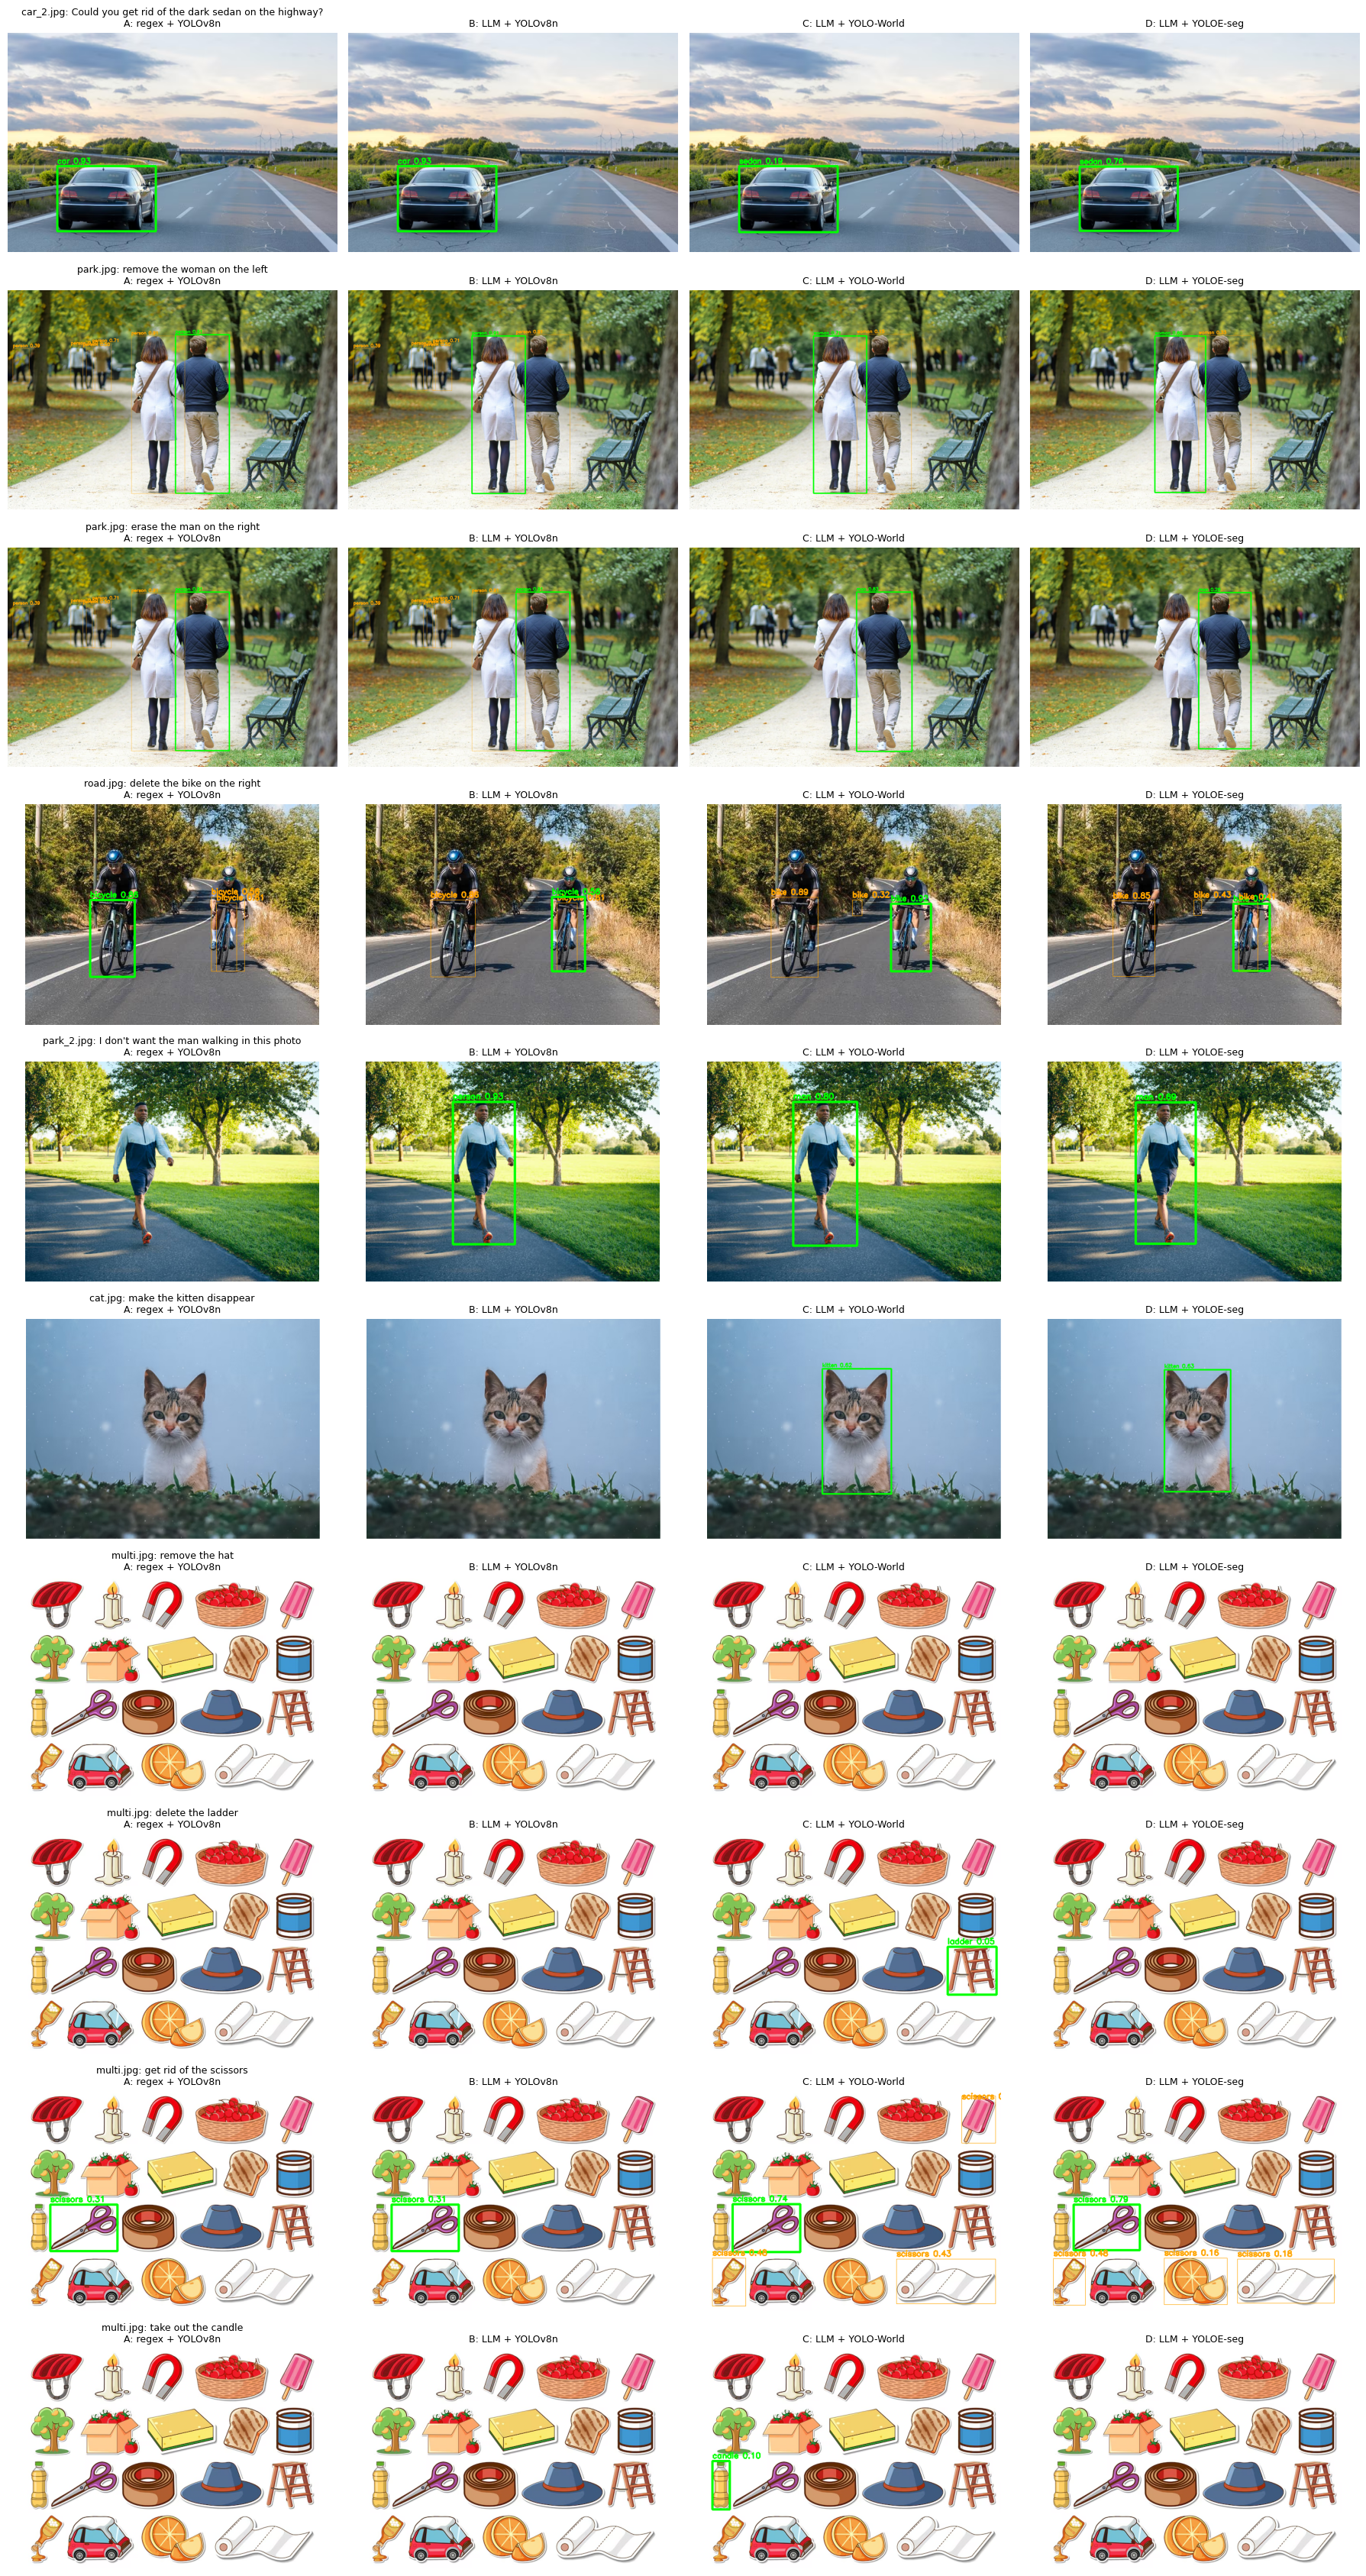

In [15]:
def ground(image, parsed, grounder):
    """grounder: 'yolov8n' (COCO class) | 'world' | 'yoloe' (open-vocabulary phrase)."""
    t0 = time.perf_counter()
    text_t = 0.0
    if grounder == "yolov8n":
        dets = detect_coco(image, parsed["coco_class"])
    else:
        dets, text_t = detect_open_vocab(image, parsed["object"] or parsed["coco_class"], grounder)
    chosen = select_detections(dets, parsed["which"], image.shape)
    return dets, chosen, time.perf_counter() - t0, text_t


GROUNDING_CASES = [
    ("car_2.jpg", "Could you get rid of the dark sedan on the highway?"),
    ("park.jpg", "remove the woman on the left"),
    ("park.jpg", "erase the man on the right"),
    ("road.jpg", "delete the bike on the right"),
    ("park_2.jpg", "I don't want the man walking in this photo"),
    ("cat.jpg", "make the kitten disappear"),
    ("multi.jpg", "remove the hat"),
    ("multi.jpg", "delete the ladder"),
    ("multi.jpg", "get rid of the scissors"),
    ("multi.jpg", "take out the candle"),
]

SYSTEMS = [
    ("A: regex + YOLOv8n", "regex", "yolov8n"),
    ("B: LLM + YOLOv8n", "llm", "yolov8n"),
    ("C: LLM + YOLO-World", "llm", "world"),
]
if YOLOE_OK:
    SYSTEMS.append(("D: LLM + YOLOE-seg", "llm", "yoloe"))

parse_cache = {}


def cached_parse(parser, instruction):
    key = (parser, instruction)
    if key not in parse_cache:
        t0 = time.perf_counter()
        try:
            p = regex_parse(instruction) if parser == "regex" else llm_parse(instruction)
        except Exception as exc:
            print(f"[{parser}] parse failed: {instruction!r} -> {exc}")
            p = None
        parse_cache[key] = (p, time.perf_counter() - t0)
    return parse_cache[key]


grounding_rows, vis_rows = [], []
for img_name, instruction in GROUNDING_CASES:
    image = read_image(img_name)
    vis = []
    for sys_name, parser, grounder in SYSTEMS:
        p, parse_t = cached_parse(parser, instruction)
        dets, chosen, det_t, text_t = [], [], 0.0, 0.0
        if p is not None and p["action"] == "remove":
            reset_text_cache()
            dets, chosen, det_t, text_t = ground(image, p, grounder)
        query = "" if p is None else (p["coco_class"] if grounder == "yolov8n" else p["object"])
        grounding_rows.append({
            "system": sys_name, "image": img_name, "instruction": instruction,
            "parsed_ok": p is not None, "query": query, "which": None if p is None else p["which"],
            "n_candidates": len(dets), "found": bool(chosen),
            "confidence": chosen[0]["confidence"] if chosen else None,
            "parse_ms": parse_t * 1000, "detect_ms": det_t * 1000, "text_encode_ms": text_t * 1000,
        })
        vis.append(draw_detections(image, dets, chosen, label=query))
    vis_rows.append(vis)

grounding_eval = pd.DataFrame(grounding_rows)
grounding_eval.to_csv(os.path.join(BENCHMARK_DIR, "e4_grounding_eval.csv"), index=False)

display(grounding_eval.groupby("system")[["parsed_ok", "found", "parse_ms", "detect_ms", "text_encode_ms"]].mean().round(2))
show_grid(vis_rows, [s[0] for s in SYSTEMS], row_titles=[f"{i}: {t}" for i, t in GROUNDING_CASES],
          cell=4.5, save_as="e4_grounding_grid.jpg")

## 4.3 End-to-end removal: LLM → open-vocabulary grounding → mask → MI-GAN

[world] car_2.jpg | Could you get rid of the dark sedan on the highway? | total=17.61s
[yoloe] car_2.jpg | Could you get rid of the dark sedan on the highway? | total=15.41s
[world] park.jpg | remove the woman on the left | total=17.38s
[yoloe] park.jpg | remove the woman on the left | total=8.49s
[world] park.jpg | erase the man on the right | total=14.17s
[yoloe] park.jpg | erase the man on the right | total=11.04s
[world] road.jpg | delete the bike on the right | total=16.38s
[yoloe] road.jpg | delete the bike on the right | total=13.30s
[world] park_2.jpg | I don't want the man walking in this photo | total=16.45s
[yoloe] park_2.jpg | I don't want the man walking in this photo | total=13.32s
[world] cat.jpg | make the kitten disappear | total=16.68s
[yoloe] cat.jpg | make the kitten disappear | total=13.72s
[world] multi.jpg | remove the hat | FAILED: No detection for object='hat' / class='none'
[yoloe] multi.jpg | remove the hat | FAILED: No detection for object='hat' / class='non

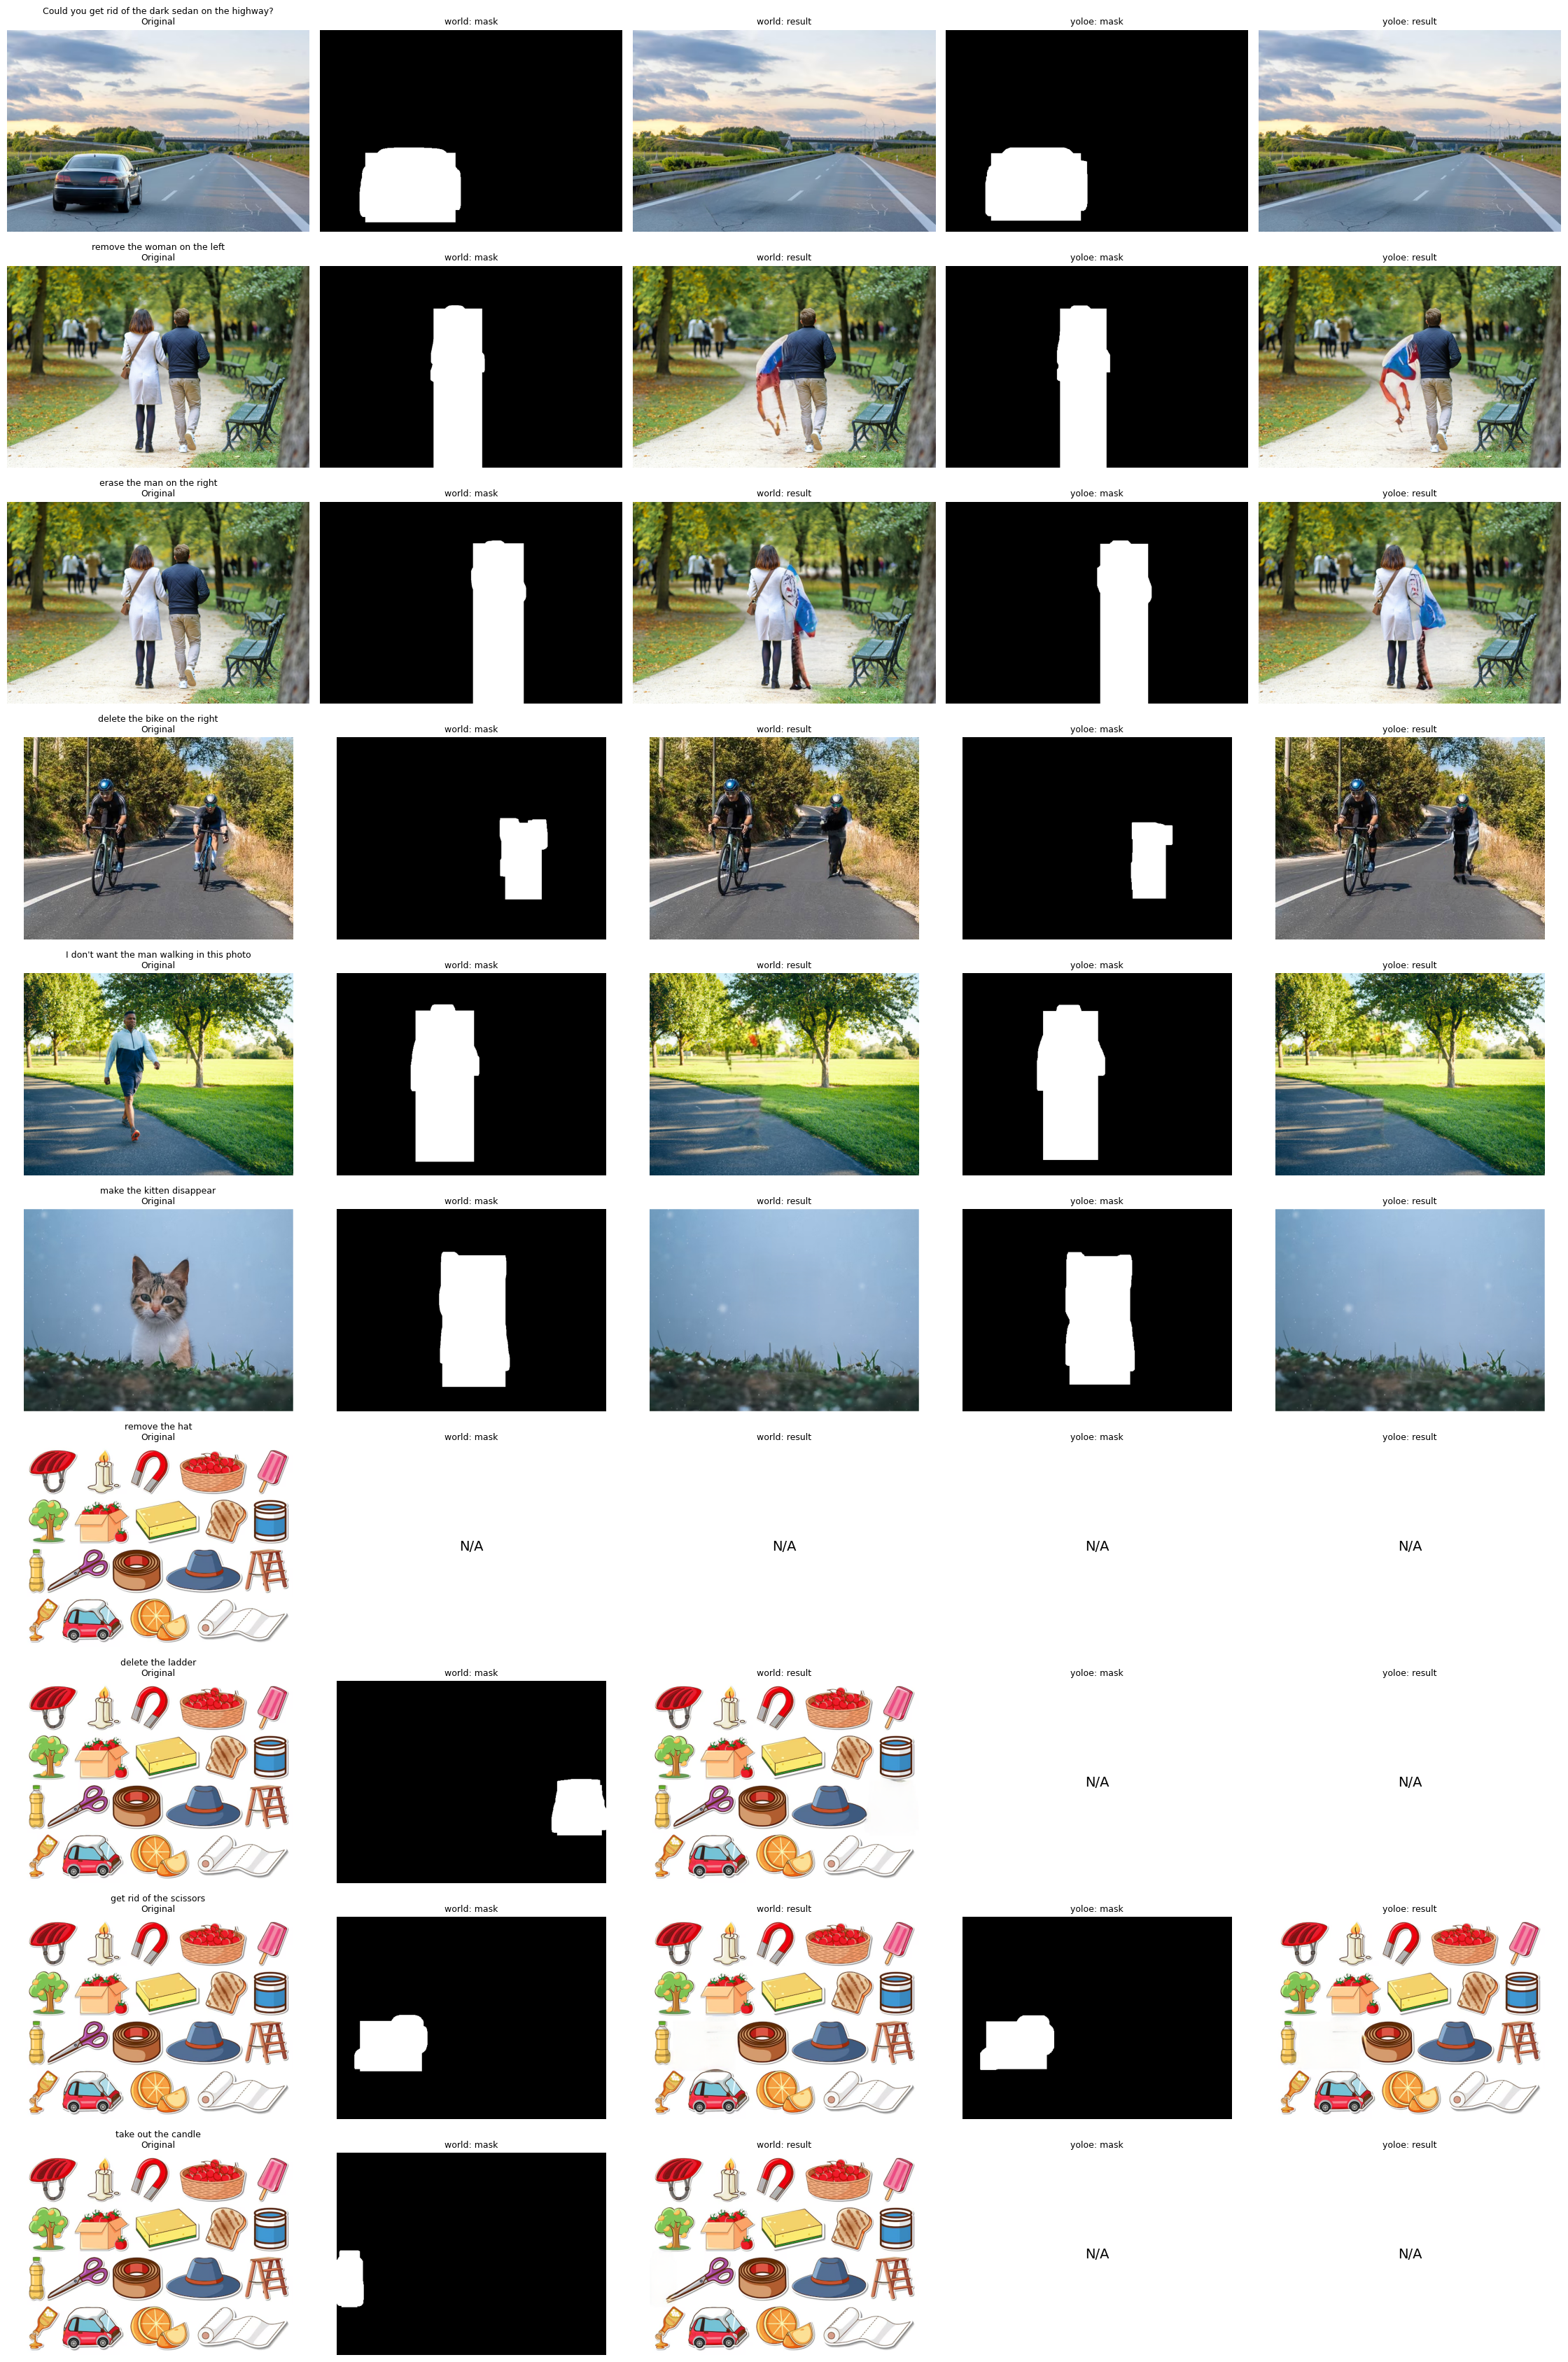

In [16]:
def e4_remove(image, instruction, parser="llm", grounder="world", mask_grow=15, shadow_ratio=0.15):
    times = {}
    t0 = time.perf_counter()
    parsed = llm_parse(instruction) if parser == "llm" else regex_parse(instruction)
    times["parse"] = time.perf_counter() - t0
    if parsed["action"] != "remove":
        raise ValueError(f"E4 handles removal; parsed action = {parsed['action']!r}")

    dets, chosen, times["detect"], text_t = ground(image, parsed, grounder)
    if not chosen:
        raise ValueError(f"No detection for object={parsed['object']!r} / class={parsed['coco_class']!r}")
    boxes = [d["bbox"] for d in chosen]

    t0 = time.perf_counter()
    if all("polygon" in d for d in chosen):          # YOLOE / YOLO-seg already gave masks
        masks = [polygon_to_mask(d["polygon"], image.shape) for d in chosen]
    else:
        masks, _ = segment_boxes(image, boxes)
    times["segment"] = time.perf_counter() - t0

    rm = build_removal_mask(masks, boxes, image.shape, grow=mask_grow, shadow_ratio=shadow_ratio)
    output, times["inpaint"] = migan_inpaint(image, rm)
    times["total"] = times["parse"] + times["detect"] + times["segment"] + times["inpaint"]

    meta = {
        "parser": parser, "grounder": grounder, "object": parsed["object"], "coco_class": parsed["coco_class"],
        "which": parsed["which"], "n_candidates": len(dets), "n_selected": len(chosen),
        "confidence": max(d["confidence"] for d in chosen), "text_encode_sec": text_t,
        **{f"{k}_sec": v for k, v in times.items()},
    }
    return output, rm, meta


E2E_GROUNDERS = ["world"] + (["yoloe"] if YOLOE_OK else [])
e2e_rows, e2e_titles = [], ["Original"]
for g in E2E_GROUNDERS:
    e2e_titles += [f"{g}: mask", f"{g}: result"]

for img_name, instruction in GROUNDING_CASES:
    image = read_image(img_name)
    row = [image]
    for g in E2E_GROUNDERS:
        try:
            out, rm, meta = e4_remove(image, instruction, parser="llm", grounder=g)
            save_image(out, f"{Path(img_name).stem}_{g}_{slug(instruction)}.jpg")
            row += [rm, out]
            print(f"[{g}] {img_name} | {instruction} | total={meta['total_sec']:.2f}s")
        except Exception as exc:
            row += [None, None]
            print(f"[{g}] {img_name} | {instruction} | FAILED: {exc}")
    e2e_rows.append(row)

show_grid(e2e_rows, e2e_titles, row_titles=[t for _, t in GROUNDING_CASES], cell=4.5,
          save_as="e4_removal_grid.jpg")

## 4.4 CPU benchmark

System A is the E3 pipeline, measured here as the reference. Each case gets 1 warm-up run and 3 timed runs.

The text embedding is cached per phrase, the same way a deployed app would repeat a prompt. The cost of encoding a new phrase is in `e4_grounding_eval.csv` (`text_encode_ms`).

In [17]:
BENCH_CASES = [
    ("car_2.jpg", "Could you get rid of the dark sedan on the highway?"),
    ("park_2.jpg", "I don't want the man walking in this photo"),
    ("multi.jpg", "remove the hat"),
    ("cat.jpg", "make the kitten disappear"),
]
BENCH_SYSTEMS = [s for s in SYSTEMS if s[0][0] in "ACD"]

SIZE_A = YOLO_SIZE_MB + MOBILE_SAM_SIZE_MB + MIGAN_SIZE_MB
SYSTEM_SIZE_MB = {
    "A: regex + YOLOv8n": SIZE_A,
    "B: LLM + YOLOv8n": SIZE_A + LLM_SIZE_MB,
    "C: LLM + YOLO-World": LLM_SIZE_MB + WORLD_SIZE_MB + WORLD_TEXT_MB + MOBILE_SAM_SIZE_MB + MIGAN_SIZE_MB,
}
if YOLOE_OK:
    SYSTEM_SIZE_MB["D: LLM + YOLOE-seg"] = LLM_SIZE_MB + YOLOE_SIZE_MB + YOLOE_TEXT_MB + MIGAN_SIZE_MB


def benchmark_e4(cases, systems, iterations=3, warmup=1):
    rows = []
    for sys_name, parser, grounder in systems:
        for img_name, instruction in cases:
            image = read_image(img_name)
            try:
                for _ in range(warmup):
                    e4_remove(image, instruction, parser=parser, grounder=grounder)
                for it in range(iterations):
                    _, _, meta = e4_remove(image, instruction, parser=parser, grounder=grounder)
                    rows.append({"variant": f"E4-{sys_name}", "image": img_name, "instruction": instruction,
                                 "iteration": it, "model_size_MB": SYSTEM_SIZE_MB[sys_name], "error": "", **meta})
            except Exception as exc:
                rows.append({"variant": f"E4-{sys_name}", "image": img_name, "instruction": instruction,
                             "model_size_MB": SYSTEM_SIZE_MB[sys_name], "error": str(exc)[:120]})
            print(f"{sys_name} | {img_name} | {rows[-1].get('error') or 'ok'}")
    return pd.DataFrame(rows)


e4_bench = benchmark_e4(BENCH_CASES, BENCH_SYSTEMS)
e4_bench.to_csv(os.path.join(BENCHMARK_DIR, "e4_benchmark.csv"), index=False)

ok = e4_bench[e4_bench.error == ""]
summary = ok.groupby("variant")[["parse_sec", "detect_sec", "segment_sec", "inpaint_sec", "total_sec"]].mean() * 1000
summary.columns = [c.replace("_sec", "_ms") for c in summary.columns]
summary["success_rate_%"] = (e4_bench.groupby("variant")["error"].apply(lambda s: (s == "").mean()) * 100).round(0)
summary["model_size_MB"] = e4_bench.groupby("variant")["model_size_MB"].first()
display(summary.round(1))

A: regex + YOLOv8n | car_2.jpg | ok
A: regex + YOLOv8n | park_2.jpg | Regex parser could not understand: "I don't want the man walking in this photo"
A: regex + YOLOv8n | multi.jpg | No detection for object='hat' / class='none'
A: regex + YOLOv8n | cat.jpg | Regex parser could not understand: 'make the kitten disappear'
C: LLM + YOLO-World | car_2.jpg | ok
C: LLM + YOLO-World | park_2.jpg | ok
C: LLM + YOLO-World | multi.jpg | No detection for object='hat' / class='none'
C: LLM + YOLO-World | cat.jpg | ok
D: LLM + YOLOE-seg | car_2.jpg | ok
D: LLM + YOLOE-seg | park_2.jpg | ok
D: LLM + YOLOE-seg | multi.jpg | No detection for object='hat' / class='none'
D: LLM + YOLOE-seg | cat.jpg | ok


,parse_ms,detect_ms,segment_ms,inpaint_ms,total_ms,success_rate_%,model_size_MB
variant,,,,,,,
E4-A: regex + YOLOv8n,0.2,186.1,3817.1,2145.9,6149.2,50.0,71.9
E4-C: LLM + YOLO-World,8469.8,501.6,3615.9,2406.5,14993.7,90.0,896.6
E4-D: LLM + YOLOE-seg,9699.0,540.9,0.2,1655.4,11895.4,90.0,1093.9


In [18]:
sizes = pd.DataFrame(LOAD_STATS)
sizes.to_csv(os.path.join(BENCHMARK_DIR, "e4_model_sizes.csv"), index=False)
display(sizes.round(2))
print(pd.Series(SYSTEM_SIZE_MB, name="total_model_MB").round(1))

,component,size_MB,params_M,ram_added_MB
0,YOLOv8n,6.25,3.16,18.24
1,MobileSAM,38.84,10.13,89.50
2,MI-GAN (ONNX),26.78,NaN,46.90
3,YOLO-World-S v2 (+ CLIP text encoder),362.30,164.04,717.57
4,YOLOE-11S-seg (+ text encoder),598.50,13.71,463.12
5,Qwen2.5-0.5B-Instruct Q4_K_M (llama.cpp),468.64,NaN,488.75


A: regex + YOLOv8n       71.9
B: LLM + YOLOv8n        540.5
C: LLM + YOLO-World     896.6
D: LLM + YOLOE-seg     1093.9
Name: total_model_MB, dtype: float64


## Observations (fill in after running)

* **Parser:**
  * Regex fully-correct accuracy: **__ %**. It fails on: …
  * LLM accuracy: **__ %**, at **__ ms** per instruction and **__ MB**.
* **Grounding:**
  * YOLOv8n can't find: hat / ladder / candle.
  * YOLO-World finds: …
  * Wrong picks: …
* **Instance selection:** the `left` / `right` rule ignores small background people, because instances smaller than 20% of the largest box's area are skipped.
* **Cost of natural language:** + __ ms latency and + __ MB for the LLM, and + __ MB for the YOLO-World text encoder.
* **Decision for the final pipeline:**
  * Use the LLM parser, with regex as the fallback.
  * Send COCO classes to the fast YOLOv8n path.
  * Use open-vocabulary grounding only when `coco_class == "none"`, or when the fast path finds nothing.